In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns

In [2]:
df = pd.read_csv("customer_churn_data.csv")
df.tail()

,CustomerID,Age,Gender,Tenure,MonthlyCharges,ContractType,InternetService,TotalCharges,TechSupport,Churn
995,996,42,Male,41,37.14,Month-to-Month,Fiber Optic,1522.74,Yes,Yes
996,997,62,Male,9,80.93,Month-to-Month,NaN,728.37,No,Yes
997,998,51,Female,15,111.72,Month-to-Month,Fiber Optic,1675.80,Yes,Yes
998,999,39,Male,68,65.67,One-Year,NaN,4465.56,No,Yes
999,1000,50,Male,1,56.67,Month-to-Month,NaN,56.67,No,Yes


In [3]:
df.dtypes

CustomerID           int64
Age                  int64
Gender                 str
Tenure               int64
MonthlyCharges     float64
ContractType           str
InternetService        str
TotalCharges       float64
TechSupport            str
Churn                  str
dtype: object

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerID       1000 non-null   int64  
 1   Age              1000 non-null   int64  
 2   Gender           1000 non-null   str    
 3   Tenure           1000 non-null   int64  
 4   MonthlyCharges   1000 non-null   float64
 5   ContractType     1000 non-null   str    
 6   InternetService  703 non-null    str    
 7   TotalCharges     1000 non-null   float64
 8   TechSupport      1000 non-null   str    
 9   Churn            1000 non-null   str    
dtypes: float64(2), int64(3), str(5)
memory usage: 78.3 KB


In [5]:
df['InternetService'].unique()

<StringArray>
['Fiber Optic', 'DSL', nan]
Length: 3, dtype: str

In [6]:
df.isna().sum()

CustomerID           0
Age                  0
Gender               0
Tenure               0
MonthlyCharges       0
ContractType         0
InternetService    297
TotalCharges         0
TechSupport          0
Churn                0
dtype: int64

In [7]:
df["InternetService"].dtype
df["InternetService"]=df["InternetService"].fillna("")

In [8]:
df["InternetService"].isna().sum()

np.int64(0)

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.describe()

,CustomerID,Age,Tenure,MonthlyCharges,TotalCharges
count,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000
mean,500.500000,44.674000,18.97300,74.391290,1404.364060
std,288.819436,9.797741,18.89257,25.712083,1571.755048
min,1.000000,12.000000,0.00000,30.000000,0.000000
25%,250.750000,38.000000,5.00000,52.357500,345.217500
50%,500.500000,45.000000,13.00000,74.060000,872.870000
75%,750.250000,51.000000,26.00000,96.102500,1900.175000
max,1000.000000,83.000000,122.00000,119.960000,12416.250000


In [11]:
numeric_columns = df.select_dtypes(include='number')
numeric_columns

,CustomerID,Age,Tenure,MonthlyCharges,TotalCharges
0,1,49,4,88.35,353.40
1,2,43,0,36.67,0.00
2,3,51,2,63.79,127.58
3,4,60,8,102.34,818.72
4,5,42,32,69.01,2208.32
...,...,...,...,...,...
995,996,42,41,37.14,1522.74
996,997,62,9,80.93,728.37
997,998,51,15,111.72,1675.80
998,999,39,68,65.67,4465.56


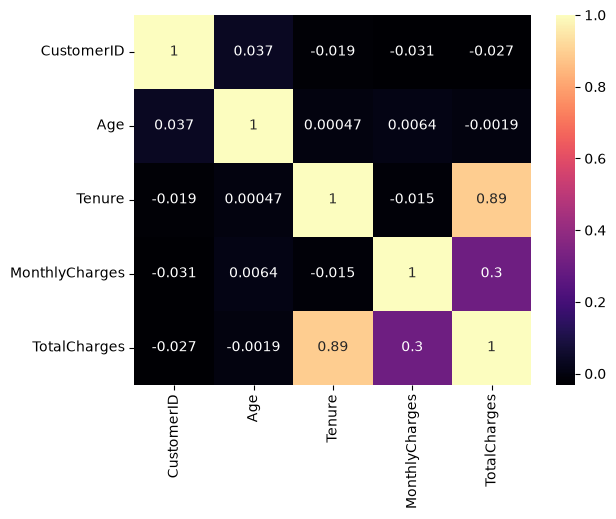

In [12]:
corr_matrix=numeric_columns.corr()
sns.heatmap(corr_matrix ,cmap='magma', annot=True)
plt.show()

In [13]:
df["Churn"].value_counts()

Churn
Yes    883
No     117
Name: count, dtype: int64

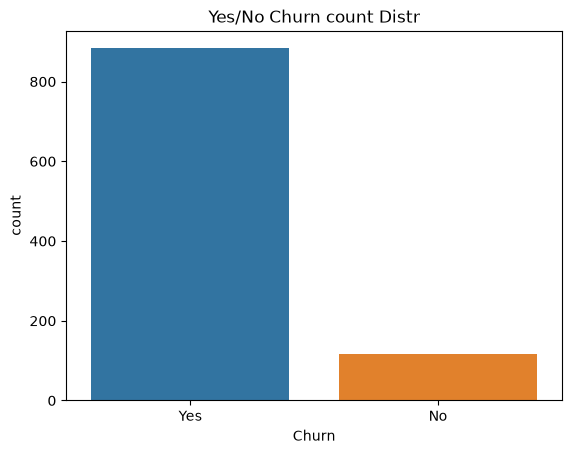

In [14]:
sns.countplot(data=df, x="Churn", hue="Churn")
plt.title("Yes/No Churn count Distr")

plt.show()

In [15]:
df.groupby("Churn")["MonthlyCharges"].mean()
# df.columns


Churn
No     62.54641
Yes    75.96077
Name: MonthlyCharges, dtype: float64

In [16]:
df.groupby(["Churn","Gender"])["MonthlyCharges"].mean()
df.groupby(["Churn","ContractType"])["MonthlyCharges"].mean()

Churn  ContractType  
No     One-Year          62.113662
       Two-Year          63.214348
Yes    Month-to-Month    75.909198
       One-Year          77.636330
       Two-Year          73.760000
Name: MonthlyCharges, dtype: float64

In [17]:
df.groupby("Churn")["Tenure"].mean()

Churn
No     30.264957
Yes    17.476784
Name: Tenure, dtype: float64

<Axes: xlabel='Tenure', ylabel='Density'>

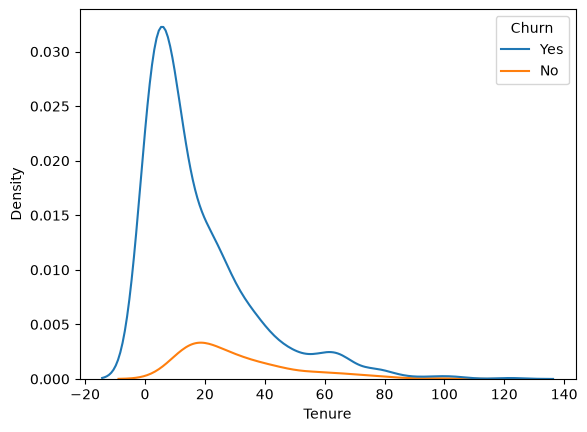

In [18]:
sns.kdeplot(data=df, x="Tenure",  hue="Churn")

In [19]:
df.groupby("Churn")["Age"].mean()

Churn
No     43.487179
Yes    44.831257
Name: Age, dtype: float64

In [20]:
pd.crosstab(df["InternetService"], df["Churn"])

Churn,No,Yes
InternetService,,
,0,297
DSL,48,260
Fiber Optic,69,326


In [21]:
categorical_columns=df.drop(columns=numeric_columns.columns)
categorical_columns.columns

Index(['Gender', 'ContractType', 'InternetService', 'TechSupport', 'Churn'],
      dtype='str')

Text(0, 0.5, 'Percentage')

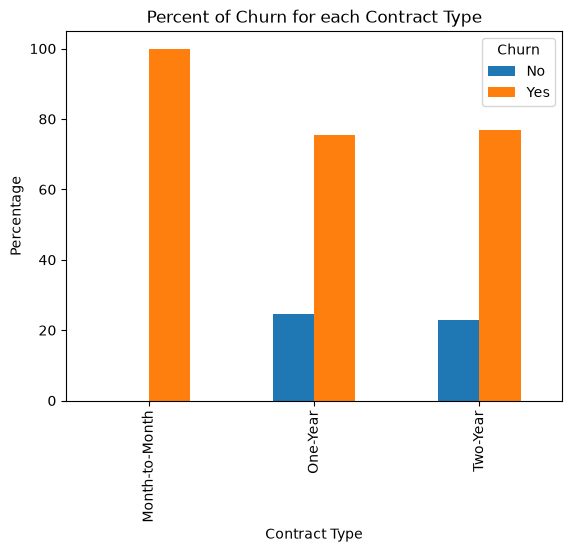

In [22]:
ct=pd.crosstab(df["ContractType"],df["Churn"],normalize="index")*100
ct.plot(kind="bar")
plt.title("Percent of Churn for each Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage")
# Shows what percent of each contract type is Churn

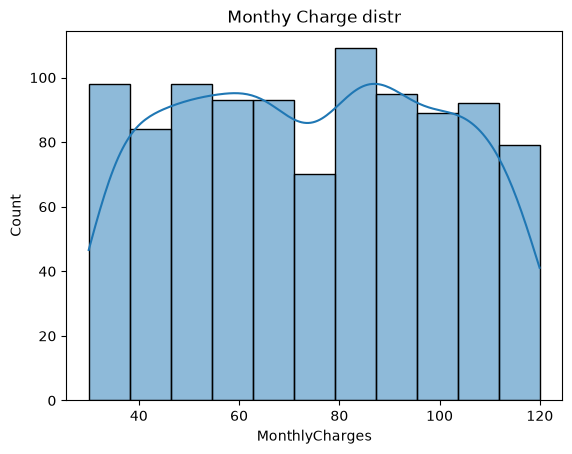

In [23]:
sns.histplot(data=df, x="MonthlyCharges",  kde=True)
plt.title("Monthy Charge distr")
plt.show()

In [24]:
ct1=pd.crosstab(df["Churn"], df["TechSupport"], normalize="index")*100
# corr_matrix

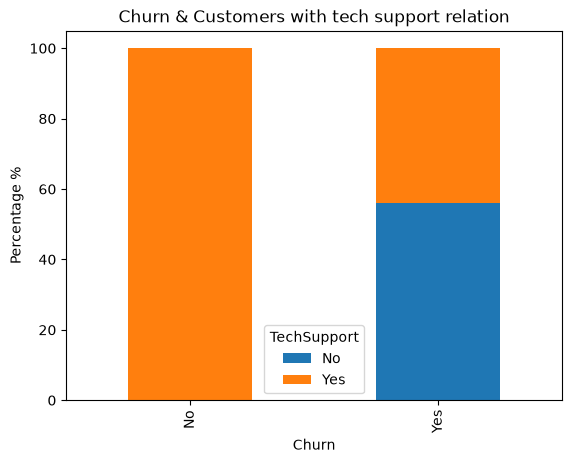

In [25]:
ct1.plot(kind="bar", stacked=True)
plt.title("Churn & Customers with tech support relation")
plt.ylabel("Percentage %")
plt.show()

In [26]:
X=df.drop(columns=["CustomerID", "Churn"])
y=df["Churn"]
X.columns


Index(['Age', 'Gender', 'Tenure', 'MonthlyCharges', 'ContractType',
       'InternetService', 'TotalCharges', 'TechSupport'],
      dtype='str')

In [27]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
X["Gender"]=le.fit_transform(X["Gender"])
X["TechSupport"]=le.fit_transform(X["TechSupport"])
y=le.fit_transform(y)


In [28]:
X.head()

,Age,Gender,Tenure,MonthlyCharges,ContractType,InternetService,TotalCharges,TechSupport
0,49,1,4,88.35,Month-to-Month,Fiber Optic,353.40,1
1,43,1,0,36.67,Month-to-Month,Fiber Optic,0.00,1
2,51,0,2,63.79,Month-to-Month,Fiber Optic,127.58,0
3,60,0,8,102.34,One-Year,DSL,818.72,1
4,42,1,32,69.01,Month-to-Month,,2208.32,0


In [29]:
X=pd.get_dummies(X, columns=["ContractType", "InternetService"])

In [30]:
X=X.astype(int)
y=pd.Series(y)
X.head()
y.head()

0    1
1    1
2    1
3    1
4    1
dtype: int64

In [31]:
print(X.shape)
print(y.shape)
print(X.isna().sum())
print(y.isna().sum())

(1000, 12)
(1000,)
Age                            0
Gender                         0
Tenure                         0
MonthlyCharges                 0
TotalCharges                   0
TechSupport                    0
ContractType_Month-to-Month    0
ContractType_One-Year          0
ContractType_Two-Year          0
InternetService_               0
InternetService_DSL            0
InternetService_Fiber Optic    0
dtype: int64
0


In [32]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [33]:
print(X_train.shape," ", X_test.shape)
print(y_train.shape," ",y_test.shape)

(800, 12)   (200, 12)
(800,)   (200,)


In [34]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

In [35]:
import warnings
warnings.filterwarnings("ignore")

In [36]:
# saving the scaler so we can reuse the exact same scaling parameters during deployment
import joblib

joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']

In [37]:
from sklearn.metrics import accuracy_score

def modelperformance(predictions):
    print("Accuracy score of model is {}".format(
        accuracy_score(y_test, predictions)
    ))

In [38]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

models = {
    "Logistic Regression": LogisticRegression(),
    "KNN": KNeighborsClassifier(),
    "Naive Bayes": GaussianNB(),
    "SVM": SVC()
}


In [39]:
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    print(f"\n{name}")
    modelperformance(predictions)


Logistic Regression
Accuracy score of model is 0.965

KNN
Accuracy score of model is 0.97

Naive Bayes
Accuracy score of model is 0.87

SVM
Accuracy score of model is 0.965


In [40]:
from sklearn.metrics import classification_report

for name, model in models.items():
    predictions = model.predict(X_test)

    print(f"\n{name}")
    print(classification_report(y_test, predictions))


Logistic Regression
              precision    recall  f1-score   support

           0       1.00      0.70      0.82        23
           1       0.96      1.00      0.98       177

    accuracy                           0.96       200
   macro avg       0.98      0.85      0.90       200
weighted avg       0.97      0.96      0.96       200


KNN
              precision    recall  f1-score   support

           0       0.90      0.83      0.86        23
           1       0.98      0.99      0.98       177

    accuracy                           0.97       200
   macro avg       0.94      0.91      0.92       200
weighted avg       0.97      0.97      0.97       200


Naive Bayes
              precision    recall  f1-score   support

           0       0.47      1.00      0.64        23
           1       1.00      0.85      0.92       177

    accuracy                           0.87       200
   macro avg       0.73      0.93      0.78       200
weighted avg       0.94      0.87  

In [41]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []

for name, model in models.items():

    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions)
    })

comparison_df = pd.DataFrame(results)
comparison_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.965,0.961957,1.000000,0.980609
1,KNN,0.970,0.977654,0.988701,0.983146
2,Naive Bayes,0.870,1.000000,0.853107,0.920732
3,SVM,0.965,0.961957,1.000000,0.980609


In [42]:
from sklearn.model_selection import GridSearchCV


In [43]:
param_grid = {
    "n_neighbors": [3, 5, 7, 9, 11, 13, 15],
    "weights": ["uniform", "distance"],
    "metric": ["euclidean", "manhattan"]
}

In [44]:
knn = KNeighborsClassifier()

grid_search = GridSearchCV(
    estimator=knn,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

In [45]:
grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",KNeighborsClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'metric': ['euclidean', 'manhattan'], 'n_neighbors': [3, 5, ...], 'weights': ['uniform', 'distance']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Cont

In [46]:
print(grid_search.best_params_)
print(grid_search.best_score_)

{'metric': 'manhattan', 'n_neighbors': 7, 'weights': 'distance'}
0.9782300078752544


In [47]:
best_knn = grid_search.best_estimator_

In [48]:
knn_predictions = best_knn.predict(X_test)

print(classification_report(y_test, knn_predictions))

              precision    recall  f1-score   support

           0       1.00      0.78      0.88        23
           1       0.97      1.00      0.99       177

    accuracy                           0.97       200
   macro avg       0.99      0.89      0.93       200
weighted avg       0.98      0.97      0.97       200



In [49]:
joblib.dump(best_knn, "model.pkl")

['model.pkl']

In [50]:
feature_order = X.columns.tolist()
feature_order

['Age',
 'Gender',
 'Tenure',
 'MonthlyCharges',
 'TotalCharges',
 'TechSupport',
 'ContractType_Month-to-Month',
 'ContractType_One-Year',
 'ContractType_Two-Year',
 'InternetService_',
 'InternetService_DSL',
 'InternetService_Fiber Optic']